# 280. Time split: would kmerseek have placed Pfam domains before Pfam did?

There is no answer key for proteins nobody has characterized, so a search over them cannot
be scored. A time split makes one. We take proteins that had no Pfam domain in an old Pfam
release and gained one in a later release, search them against the reference as it was at
the old release, and score each tool against what the later release found. CAFA scores
function prediction the same way (Zhou et al. 2019, *Genome Biology* 20: 244, https://doi.org/10.1186/s13059-019-1835-8).

**Data.**

- **t0** = Pfam 33.1 (May 2020), built on UniProtKB reference proteomes 2019_08, 18,259
  Pfam-A families. Queries are Pfam 33.1 `pfamseq` sequences with no row in its
  `Pfam-A.regions.tsv.gz`.
- **t1** = Pfam 38.2 (data files dated 22 January 2026, published June 2026), built on
  reference proteomes 2025_03, 30,134 Pfam-A families. A query gained a domain when its
  identical sequence (same MD5) has a row in the 38.2 regions file.
- **Reference searched by every tool**: Swiss-Prot as of UniProt release 2019_08
  (`uniprot_sprot-only2019_08.tar.gz`), with the Pfam 33.1 domains on each protein from
  `Pfam-A.regions.uniprot.tsv.gz`.
- **kmerseek build**: `docker.io/olgabot/kmerseek:0.4.0-rc5`
  (`sha256:7855826572644933e0c71926102b90174e650c144ae90b3641b760bd9f463afb`), the build
  the dark-set 0.4 run uses.
- Code: [`nextflow-runs/time-split-pfam/`](../nextflow-runs/time-split-pfam/).

**Scoring, fixed before any search.** A tool *transfers* family F to a query region when a
hit's interval on the target overlaps a t0 domain of F on that target. An instance is
*found* when a tool transfers the same family and at least half of the call's residues lie
inside the t1 domain. A call's residues are the transferred target domain placed on the
query through the hit, not the whole hit (changed 2026-10-14, see below). Errors are counted on decoys only (one dipeptide-shuffled copy per
query, which keeps every adjacent residue pair), because t1 Pfam is not complete: a call
t1 does not confirm on a real query is not proof of an error, but any transfer to a decoy
is one. Each tool's score cutoff is set on the *tune* half of the queries so decoys receive
at most 1 family transfer per 100 decoy queries; recall is reported on the *test* half. The
halves are fixed by the first byte of SHA-1(accession): even goes to tune.

**Search settings, fixed 2026-10-12 before any search (Olga's choices after Stop 1).**

- kmerseek: all 19 alphabets. Each alphabet's k-sizes run from k_min to k_max of
  [notebook 274](https://github.com/seanome/2024-kmerseek-analysis/blob/olgabot/ksizes-per-alphabet-274/notebooks/274_ksizes_to_test_per_alphabet_human_swissprot.ipynb) (PR 101)'s table (the one the dark-set run uses);
  where that range holds more than 5 k-sizes, every other one, starting at k_min. That is
  128 alphabet-k pairs. Scaled 1, low-complexity mask off. Each index is searched twice:
  *exact* (shared k-mers only) and *extend* (ungapped extension with mismatch penalty
  C_opt, the log-odds penalty from the alphabet's copy rate in Pfam seed pairs at 20-30%
  identity, and X-drop 4 x C_opt). Search filters as the dark-set run: threshold 0,
  at least 2 shared k-mers, query p-value at most 0.05, region score at least 1.3.
- Score each cutoff is set on (higher is better): exact `region_tfidf` (was `region_poisson_score`; changed 2026-10-14, see below); extend
  -log10(`region_evalue`); MMseqs2, phmmer and hmmscan -log10 of the hit's (domain)
  E-value.
- MMseqs2 `-s 7 --num-iterations 1 -e 10` (was 3 rounds; changed 2026-10-14, see below); phmmer `--domE 0.001`; hmmscan with the Pfam
  33.1 models, `-E 0.001 --domE 0.001`, no `--cut_ga`.

**Predictions, written before any search.**

- **P1.** Most instances sit below 30% identity to the closest t0 Swiss-Prot domain of the
  same family.
- **P2.** hmmscan with the t0 Pfam models (no gathering thresholds, `-E 0.001 --domE
  0.001`) finds the largest share of instances.
- **P3.** Over all instances at the matched error rate, kmerseek finds fewer than MMseqs2.
  Figure 3 says kmerseek stops working near 30% identity.
- **P4, the claim kmerseek needs.** For Motif, Disordered and Repeat families, and for
  regions under 60 aa, kmerseek's *unique finds* (instances found by kmerseek and by no
  other tool, each at its own matched cutoff) exceed the number expected from its decoys,
  with a 95% interval above zero, on the test half.

**Which kmerseek setting P4 is tested on (Olga, 2026-10-13, before the test half was read).**
There are 256 kmerseek search settings, so P4 is tested on one setting chosen on the tune
half only:

1. An instance counts toward P4 when its Pfam type at t1 is Motif, Disordered or Repeat, or
   its t1 region is under 60 aa.
2. For each kmerseek setting, at its own matched cutoff (set on the tune half's decoys), count
   its *unique finds* among the tune half's P4 instances: found by this setting and by none of
   MMseqs2, phmmer and hmmscan, each at its own matched cutoff.
3. The number expected by chance is the setting's decoy transfer rate at that cutoff (family
   transfers per decoy query, tune half) times the number of real tune-half queries that carry
   a P4 instance.
4. The chosen setting has the largest unique finds minus expected. Ties go to the lower decoy
   transfer rate, then to the setting name in alphabetical order.
5. P4 is read once, on the test half, for that setting alone: unique finds minus the number
   expected from the test half's decoys. The 95% interval comes from 10,000 bootstrap
   resamples (seed 280) of the test half's real queries and, independently, of its decoys.
   P4 holds when the interval's lower end is above zero.

**Three changes after the pilot's tune half, before the test half was read (Olga, 2026-10-14).**

1. *A call is the target domain placed on the query, not the whole hit.* With the whole hit as
   the call, all 35 kmerseek settings' tune-half unique finds came from three instances
   (LysM in A0A2K6L9H6; LRR_1 64-86 and 88-110 in A0A078HBQ0) where MMseqs2 and phmmer did
   transfer the family, but in hits 47 aa or longer, so under half of each hit lay inside the
   23-41 aa domain. The scorer now takes the part of the target domain the hit covers and
   places it on the query (exact for gapless kmerseek regions; along the straight line
   between the hit's ends for gapped MMseqs2 and phmmer hits).
2. *MMseqs2 runs one round.* Its 3-round profile search gave dipeptide-shuffled tune decoys
   hits down to E 1e-22, which set its matched cutoff at E 1.5e-22. With one round no tune
   decoy hit is below E 0.026.

3. *The exact arm is scored on `region_tfidf`.* kmerseek 0.4.0-rc5 computes the region
   Poisson tail as 1 - CDF, which is 0 for any p below about 1e-16 and then floored, so every
   such region scores 307.65 and no score between about 16 and 307 occurs. In 102 of 107 exact
   settings, two or more tune decoy pairs sat at 307.65, which put the matched cutoff above
   every possible score. Exact rows carry no E-value (the fit is for extension only).

Evidence: PR 121 comments of 2026-10-13 and 2026-10-14 and the tables in
`nextflow-runs/time-split-pfam/tables/pilot_partial_2026-10-13/`.

**The full run as a leaderboard dataset (Olga's prompt of 2026-10-16; written before the
test half is read).** The leaderboard needs one row per tool and setting, not a sweep.

1. *One kmerseek alphabet-k pair per alphabet.* For each alphabet, the k whose extend search
   found the most tune-half pilot instances at its matched cutoff; ties go to more P4
   instances, then to the larger k. That index is searched twice, extend and exact (exact on
   `region_tfidf`): 19 pairs, 38 settings, none of them one of the five settings the pilot
   skipped (`bin/choose_leaderboard_settings.py`, `assets/leaderboard_settings.tsv`). Seen
   before the rule was written: the per-setting found counts of 186 pilot settings (9ee53bd).
2. *Every tool is scored on the test half, once.* Recall per tool and setting on all
   test-half instances, per Pfam type at t1 and per length bin, each reported twice: on all
   truth, and on the truth that neither MMseqs2 nor phmmer found at its matched cutoff
   (`bin/leaderboard_rows.py`). hmmscan is not counted as an aligner: it searches Pfam
   33.1's own models. The rows go to the leaderboard's long table as experiment
   `time_split_pfam33_38`. `leaderboard_rows.py --half test` writes `TEST_HALF_READ` and
   refuses to run again.
3. *P4 is read as written above*, with its setting chosen on the tune half among the 38
   settings the full run searches, not among the pilot's 246.

**A second reference: the Pfam 33.1 seed sequences (written 2026-10-13, before any search
against it).** The same queries and decoys are also searched against the seed members of
every Pfam 33.1 family, gaps removed, each entry carrying its family over its whole length.
kmerseek uses the same `settings.tsv` (exact and extend), MMseqs2 and phmmer the same flags,
and every tool on every reference gets its own matched cutoff, set on the tune half as
above. hmmscan is the same run as for Swiss-Prot: it does not depend on the reference. The
question is whether searching the curated family members themselves lets kmerseek place
domains it could not place against Swiss-Prot 2019_08, and whether it gains more than
MMseqs2 and phmmer gain. Two reasons to expect little, to be measured: a smaller database
lowers the score needed for a given E-value by log2(residues in Swiss-Prot 2019_08 /
residues in the seeds) bits, but cutoffs here are set at a matched decoy rate, so this
mostly moves the cutoff, not the ranking; and Pfam builds its models from these same seed
alignments, so hmmscan with the t0 models is the trained form of what a seed search does
one sequence at a time.

Before this was written, tune-half scores from 185 of the Swiss-Prot pilot's searches had
been committed by another session (e39ac0a, `tables/pilot_partial_2026-10-13/`), and Claude,
writing this cell, read that commit's message: the best kmerseek settings there have 3 tune-half P4 instances found
by no other tool against 0.5 expected from decoys, from 52 queries carrying a P4 instance.
Later the same day, before any seed search, the titles of three more such commits were also
seen: "the 3 instances behind the tune-half unique finds" (2f06f18), "LRR_1 unique finds
come from the landing rule, not from kmerseek alone" (787bc31) and "MMseqs2 one round
removes strong decoy hits; unique finds unchanged" (2fe19f1). Their tables were not
opened. No search against the seeds had run.

- **P5.** On the test half, hmmscan with the t0 models finds more instances than MMseqs2,
  phmmer and kmerseek searching the t0 seeds, each at its matched cutoff. For kmerseek this
  is the setting with the highest tune-half recall against the seeds.
- **P6.** Going from Swiss-Prot 2019_08 to the seeds changes kmerseek's recall by no more
  than it changes MMseqs2's. Test, on the test half of the full run: for each instance,
  kmerseek's change (found on seeds minus found on Swiss-Prot: -1, 0 or 1) minus MMseqs2's
  change. Count the instances where kmerseek's change is larger and where MMseqs2's is
  larger, and compare the two counts with an exact two-sided binomial test (McNemar's test on
  these discordant instances). Each tool's own change is also reported with McNemar's test.
  The kmerseek setting is chosen on the tune half: the one whose change minus MMseqs2's
  change is largest there. The result that would support searching Pfam sequences:
  kmerseek's change larger than MMseqs2's, p < 0.05.
- **P4 with seeds**, secondary. The five steps of P4 above, with kmerseek searching the
  seeds (one setting chosen on the tune half) and MMseqs2 and phmmer on both references, and
  hmmscan, as the other tools. It does not replace P4. Two P4-type tests are now read, so
  its interval is 97.5% (bootstrap percentiles 1.25 and 98.75), and it holds when the lower
  end is above zero.

**A stratum to report, not a prediction (Olga, 2026-10-13).** Every recall number and P4's
unique finds are also split by the mean AlphaFold pLDDT of the query's residues inside the
t1 domain, from the query's AlphaFold DB model: below 50, 50 to 70, 70 or more, and no
model (none in AlphaFold DB, or a model of a different sequence). pLDDT is AlphaFold's
per-residue confidence, 0 to 100; below 50 usually means no fixed structure. Expectation,
written before reading: kmerseek's unique finds, if any, sit mostly below 50, where a
structure tool has nothing to use and where notebook 244's selected cases were. This has no
pass mark.

**Kill rule.** If P4 fails on the test half, this is written up as a negative result and
the test stops. No kmerseek settings are added, no cutoffs changed and "found" is not
redefined after the test half has been read.

**The decision this informs.** If P4 holds, the paper can claim that on proteins nobody had
characterized, kmerseek placed short features (Motif, Disordered, Repeat, or under 60 aa)
that no other tool placed, more often than chance. This is the Figure 4 candidate. If P4
fails, kmerseek adds nothing over MMseqs2 and Pfam's own models on uncharacterized proteins,
and Figure 4 reports that.


In [1]:
from pathlib import Path
import polars as pl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, NullFormatter
import pubfig as pf

pf.use_style()
STOP1 = Path("../nextflow-runs/time-split-pfam/tables/stop1")
FIG = Path("figures_280")
FUNNEL = pl.read_csv(STOP1 / "funnel.csv")
BY_TYPE = pl.read_csv(STOP1 / "funnel_by_type_length.csv")
SAMPLE = pl.read_csv(STOP1 / "proposed_sample_by_type.csv")
IDENT = pl.read_csv(STOP1 / "identity_sample.csv")
TYPES = ["Domain", "Family", "Repeat", "Motif", "Disordered", "Coiled-coil"]

## Stop 1a. The query set, step by step

Each step keeps the rows that pass it. Steps 1 to 3 count protein sequences; from step 3 on
the unit is an *instance*: one (query, family, t1 start, t1 end).

1. Every sequence in Pfam 33.1 `pfamseq`. Our MD5 (lowercase hex of the uppercase
   sequence) agreed with the t0 regions file on 1,000 of 1,000 proteins checked.
2. No row in the t0 regions file, by accession or by MD5.
3. The identical sequence has a Pfam-A domain at t1. Sequences without one are split by
   whether they are still in Pfam 38.0's `pfamseq` (the same 2025_03 reference proteomes as
   38.2): still there with no domain, or gone from the reference proteomes, so they cannot be
   checked.
4. The gained family existed at t0 (listed in Pfam 33.1). A family created after t0 cannot
   be transferred from a t0 reference by any tool.
5. The family has at least one domain on a Swiss-Prot 2019_08 protein, so a tool searching
   that reference can reach it.
7. The query's sequence is not itself in Swiss-Prot 2019_08 (no query finds itself).

How to read it: the bars are counts at each step. The x axis is spaced by ratio, so each
step of ten takes the same room. Panel c is the decision: it shows how many queries each
Pfam type has, and how many the proposed sample draws.


shape: (5, 2)
┌─────────────────────────────────┬──────────┐
│ step (sequences)                ┆ n        │
│ ---                             ┆ ---      │
│ str                             ┆ i64      │
╞═════════════════════════════════╪══════════╡
│ 1. pfamseq 33.1                 ┆ 47079205 │
│ 2. no t0 domain                 ┆ 11711072 │
│ 3. gained a domain at t1        ┆ 1269023  │
│    still no domain at t1        ┆ 8083707  │
│    left the reference proteome… ┆ 2358342  │
└─────────────────────────────────┴──────────┘
shape: (4, 2)
┌─────────────────────────────────┬─────────┐
│ step (instances)                ┆ n       │
│ ---                             ┆ ---     │
│ str                             ┆ i64     │
╞═════════════════════════════════╪═════════╡
│ 3. gained (instances)           ┆ 1494716 │
│ 4. family existed at t0         ┆ 304439  │
│ 5. family on Swiss-Prot 2019_0… ┆ 281593  │
│ 7. query not in Swiss-Prot      ┆ 280374  │
└─────────────────────────────────┴──────

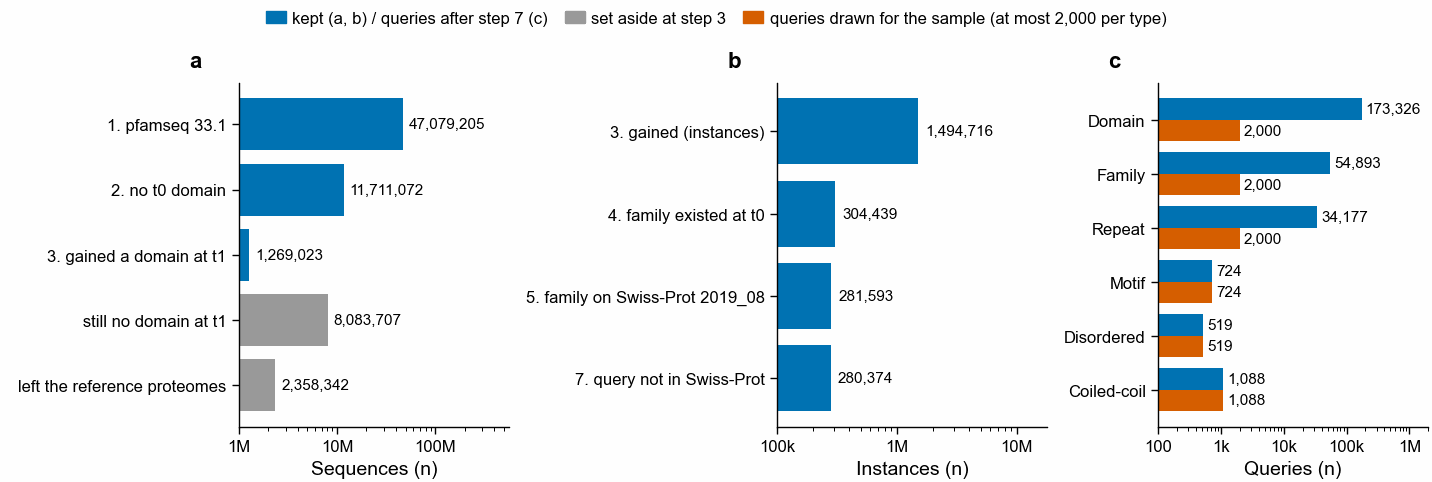

In [2]:
steps_seq = [
    ("1. pfamseq 33.1", FUNNEL.filter(pl.col("step") == "1")["n"][0]),
    ("2. no t0 domain", FUNNEL.filter(pl.col("step") == "2")["n"][0]),
    ("3. gained a domain at t1", FUNNEL.filter(pl.col("step") == "3")["n"][0]),
    ("   still no domain at t1", FUNNEL.filter(pl.col("step") == "3b")["n"][0]),
    ("   left the reference proteomes", FUNNEL.filter(pl.col("step") == "3c")["n"][0]),
]
inst = FUNNEL.filter(
    pl.col("step").is_in(["3", "4", "5", "7"])
    & pl.col("what").str.contains("instances|and the|family existed")
)
steps_inst = [
    ("3. gained (instances)", inst.filter(pl.col("step") == "3")["n"][0]),
    ("4. family existed at t0", inst.filter(pl.col("step") == "4")["n"][0]),
    ("5. family on Swiss-Prot 2019_08", inst.filter(pl.col("step") == "5")["n"][0]),
    ("7. query not in Swiss-Prot", inst.filter(pl.col("step") == "7")["n"][0]),
]
print(pl.DataFrame(steps_seq, schema=["step (sequences)", "n"], orient="row"))
print(pl.DataFrame(steps_inst, schema=["step (instances)", "n"], orient="row"))
print(SAMPLE)

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 62, ncols=3)
KEPT, DROPPED, DRAWN = pf.OKABE_ITO["blue"], pf.GREY, pf.OKABE_ITO["vermillion"]
for ax, steps, unit in (
    (axs[0], steps_seq, "Sequences"),
    (axs[1], steps_inst, "Instances"),
):
    labels = [s for s, _ in steps][::-1]
    vals = [v for _, v in steps][::-1]
    colors = [DROPPED if s.startswith("   ") else KEPT for s in labels]
    ax.barh(labels, vals, color=colors)
    ax.set_xscale("log")
    for y, v in enumerate(vals):
        ax.text(v * 1.15, y, f"{v:,}", va="center", fontsize=5.5)
    ax.set_xlim(1e5 if unit == "Instances" else 1e6, max(vals) * 12)
    ax.set_xlabel(f"{unit} (n)")
t = SAMPLE.with_columns(pl.col("pfam_type").cast(pl.Enum(TYPES))).sort(
    "pfam_type", descending=True
)
y = np.arange(t.height)
axs[2].barh(y + 0.2, t["queries_available"], height=0.4, color=KEPT)
axs[2].barh(y - 0.2, t["queries_drawn"], height=0.4, color=DRAWN)
axs[2].set_yticks(y, t["pfam_type"])
axs[2].set_xscale("log")
axs[2].set_xlabel("Queries (n)")
for yy, a, d in zip(y, t["queries_available"], t["queries_drawn"]):
    axs[2].text(a * 1.15, yy + 0.2, f"{a:,}", va="center", fontsize=5.5)
    axs[2].text(d * 1.15, yy - 0.2, f"{d:,}", va="center", fontsize=5.5)
axs[2].set_xlim(100, 2e6)


def plain_count(v, _pos):
    return f"{v / 1e6:g}M" if v >= 1e6 else f"{v / 1e3:g}k" if v >= 1e3 else f"{v:g}"


for ax in axs:
    ax.xaxis.set_major_formatter(FuncFormatter(plain_count))
    ax.xaxis.set_minor_formatter(NullFormatter())
fig.legend(
    handles=[
        Patch(color=KEPT, label="kept (a, b) / queries after step 7 (c)"),
        Patch(color=DROPPED, label="set aside at step 3"),
        Patch(
            color=DRAWN, label="queries drawn for the sample (at most 2,000 per type)"
        ),
    ],
    loc="outside upper center",
    ncol=3,
)
for ax, letter in zip(axs, "abc"):
    pf.panel_label(ax, letter)
pf.save(
    fig, FIG / "time_split_funnel_pfam33-1_to_38-2_sprot2019_08", formats=("png", "pdf")
)

## Stop 1b. Identity of each instance to its closest t0 Swiss-Prot domain

On 500 instances drawn at random (seed 280) from the 280,374 kept at step 7, the query's
t1 domain was aligned with ssearch36 (FASTA 36.3.8i, Smith-Waterman, BLOSUM62, gap open
11, extend 1) to every Swiss-Prot 2019_08 domain of the same family under Pfam 33.1. The
closest is the one with the highest bit score. *Identity* is identical columns divided by
alignment columns, gaps included, as ssearch36 and BLAST report it. Because the alignment
is local, it can cover only part of the domain, so the second reading divides the identical
columns by the whole t1 domain length.

How to read it: P1 predicted that most instances sit below 30% identity. The share left of
the dashed line in panel a answers it. Panel b shows whether the short-feature types that
P4 is about (Motif, Disordered, Repeat) sit at lower or higher identity than Domain and
Family.


shape: (9, 3)
┌──────────────┬─────┬───────┐
│ identity_bin ┆ n   ┆ share │
│ ---          ┆ --- ┆ ---   │
│ str          ┆ i64 ┆ f64   │
╞══════════════╪═════╪═══════╡
│ 0-20%        ┆ 2   ┆ 0.004 │
│ 20-30%       ┆ 93  ┆ 0.186 │
│ 30-40%       ┆ 169 ┆ 0.338 │
│ 40-50%       ┆ 116 ┆ 0.232 │
│ 50-60%       ┆ 68  ┆ 0.136 │
│ 60-70%       ┆ 28  ┆ 0.056 │
│ 70-80%       ┆ 8   ┆ 0.016 │
│ 80-90%       ┆ 10  ┆ 0.02  │
│ 90-100%      ┆ 6   ┆ 0.012 │
└──────────────┴─────┴───────┘
shape: (5, 5)
┌─────────────┬─────┬─────────────────┬─────────────────┬──────────┐
│ pfam_type   ┆ n   ┆ median_identity ┆ median_coverage ┆ under_30 │
│ ---         ┆ --- ┆ ---             ┆ ---             ┆ ---      │
│ str         ┆ i64 ┆ f64             ┆ f64             ┆ f64      │
╞═════════════╪═════╪═════════════════╪═════════════════╪══════════╡
│ Coiled-coil ┆ 5   ┆ 39.58           ┆ 0.866667        ┆ 0.2      │
│ Domain      ┆ 328 ┆ 38.17           ┆ 0.792436        ┆ 0.167683 │
│ Family      ┆ 96  ┆ 32

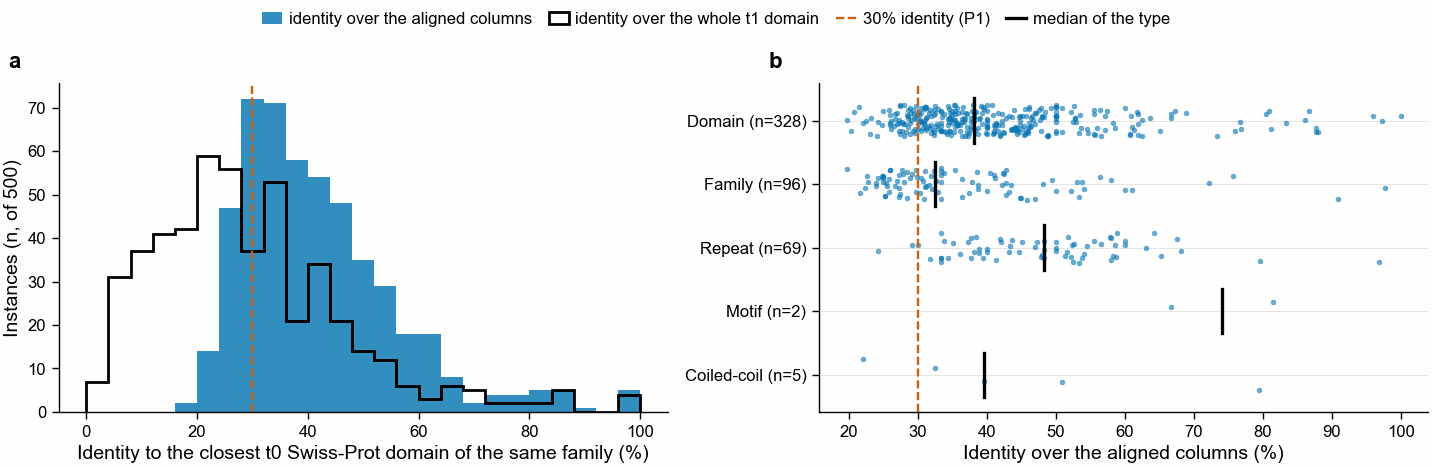

In [3]:
bins = pl.read_csv(STOP1 / "identity_bins.csv")
by_type = pl.read_csv(STOP1 / "identity_by_type.csv")
print(bins)
print(by_type)
n = IDENT.height
under30 = (IDENT["pident"] < 30).sum()
under30_dom = (IDENT["identity_over_domain"] < 30).sum()
print(
    f"identity over the aligned columns: median {IDENT['pident'].median():.1f}%, "
    f"{under30} of {n} under 30% ({100 * under30 / n:.1f}%)"
)
print(
    f"identity over the whole t1 domain: median {IDENT['identity_over_domain'].median():.1f}%, "
    f"{under30_dom} of {n} under 30% ({100 * under30_dom / n:.1f}%)"
)
print(f"aligned share of the t1 domain: median {IDENT['query_coverage'].median():.2f}")

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 60, ncols=2)
edges = np.arange(0, 102, 4)
axs[0].hist(
    IDENT["pident"],
    bins=edges,
    color=pf.OKABE_ITO["blue"],
    alpha=0.8,
    label="identity over the aligned columns",
)
axs[0].hist(
    IDENT["identity_over_domain"],
    bins=edges,
    histtype="step",
    linewidth=1,
    color=pf.OKABE_ITO["black"],
    label="identity over the whole t1 domain",
)
axs[0].axvline(
    30,
    color=pf.OKABE_ITO["vermillion"],
    linestyle="--",
    linewidth=0.8,
    label="30% identity (P1)",
)
axs[0].set_xlabel("Identity to the closest t0 Swiss-Prot domain of the same family (%)")
axs[0].set_ylabel(f"Instances (n, of {n})")
rng = np.random.default_rng(280)
order = [t for t in TYPES if t in IDENT["pfam_type"].unique().to_list()]
for i, t in enumerate(order):
    v = IDENT.filter(pl.col("pfam_type") == t)["pident"].to_numpy()
    axs[1].scatter(
        v,
        i + rng.uniform(-0.25, 0.25, len(v)),
        s=4,
        color=pf.OKABE_ITO["blue"],
        alpha=0.6,
        linewidths=0,
    )
    axs[1].plot(
        [np.median(v)] * 2,
        [i - 0.35, i + 0.35],
        color=pf.OKABE_ITO["black"],
        linewidth=1.2,
        label="median of the type" if i == 0 else None,
    )
axs[1].set_yticks(
    range(len(order)), [f"{t} (n={(IDENT['pfam_type'] == t).sum()})" for t in order]
)
for i in range(len(order)):
    axs[1].axhline(i, color="#dddddd", linewidth=0.3, zorder=0)
axs[1].axvline(30, color=pf.OKABE_ITO["vermillion"], linestyle="--", linewidth=0.8)
axs[1].set_xlabel("Identity over the aligned columns (%)")
axs[1].invert_yaxis()
pf.shared_legend(fig, ncol=4)
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
pf.save(
    fig, FIG / "time_split_identity_500_instances_sprot2019_08", formats=("png", "pdf")
)

## Stop 1c. Five instances as residues

Drawn at random (seed 281) from the 500 above. Each shows the query's t1 domain aligned to
the closest t0 Swiss-Prot domain of the same family (ssearch36 local alignment, so gaps
can appear), a match line and the count, then both in `hp_pbotc_1st_ed2` classes
(h = `ACFILMPVWY`, p = `DEGHKNQRST`) with their own match line. `^` marks the longest run
of columns, with no gap, where both residues are in the same class. kmerseek
`hp_pbotc_1st_ed2` k=19 needs a run of at least 19 such columns to share one k-mer.


In [4]:
print((STOP1 / "five_examples.txt").read_text())

Q23117 (GLoBin related, Eukaryota) t1 PF00042 Globin [Domain] residues 50-166 (117 aa)
closest t0 Swiss-Prot domain: A8XGY6/52-165   bits 43.7
query     50 RCFSRLESNCPIVSQCFQSATY--SLSTNPNGVRTVADHAKYLLQLLDKIIEG-DVDSEF---LREIGANHVCLKHESGFSTQEWDRFQEI 134
               |  ||   | | | |  |              |   | |      |      |   ||    | ||  |  |   | ||   | |  ||
Sprot     73 KIFLELEIASPKVKQIFYKAALVDAFNKDDDNTATLEVHIKLTTKFFDELLATLDDENEFVAKIRGIGSAHAILAKGSNFSSDIWERLGEI 163
27 of 91 aligned columns identical (29.7%)
hp_pbotc_1st_ed2 classes (h = ACFILMPVWY, p = DEGHKNQRST):
query        phhpphppphhhhpphhpphph--phppphpphpphhpphphhhphhpphhpp-phppph---hpphphpphhhppppphpppphpphpph
             ||| |||   | ||||| || |   |||| ||  ||  ||||  ||||||| | | ||||   |||||  |||| |||||||| |||||||
Sprot        phhhphphhphphpphhhphhhhphhppppppphphphphphppphhpphhhphppppphhhphpphpphphhhhpppphppphhpphpph
                                                                                        ^^^^^^^^
64 of 91 columns in 

## Stop A. A second reference: the Pfam 33.1 seed sequences (built, not yet searched)

`make_search_inputs.py reference-pfam-seed` reads Pfam 33.1 `Pfam-A.seed.gz` (its MD5
agreed with the release's `md5_checksums`). Each seed member becomes one entry: gap
characters removed, upper case, named `<family>__<accession>_<start>_<end>`, with one
domain row that spans the whole entry, so a hit anywhere on it transfers that family.
Members with the same sequence share one entry, which keeps a row for each family:
kmerseek 0.4.0 merges index entries with the same k-mers (kmerseek PR 141), so they would
not be searched apart anyway. A member is dropped when its accession is a query, or when its
residues lie inside any sequence the searches use (pilot, full and smoke sets, decoys
included).

The bits a smaller database saves are arithmetic, not a measurement: an E-value is the
database size times the chance of the score, so dividing the database by R lowers the score
needed for the same E-value by log2(R) bits.

How to read the figure: panel a compares the two references' entry lengths (a seed entry is
one domain, a Swiss-Prot entry one protein); the totals in the legend are what sets the
bits saved. Panel b is the sizing check: spectrum load (how often each k-mer recurs, the
dark-set predictor of kmerseek search memory) for both references at four settings; points
above the diagonal mean the seeds need more search memory than Swiss-Prot.


shape: (11, 2)
┌─────────────────────────────────┬───────────┐
│ count                           ┆ n         │
│ ---                             ┆ ---       │
│ str                             ┆ i64       │
╞═════════════════════════════════╪═══════════╡
│ Pfam 33.1 seed members          ┆ 1240873   │
│   dropped: accession is a quer… ┆ 48        │
│   dropped: residues inside a q… ┆ 30        │
│   kept                          ┆ 1240795   │
│ entries (distinct sequences)    ┆ 1239872   │
│ …                               ┆ …         │
│   entries in more than one fam… ┆ 2         │
│ families with an entry          ┆ 18259     │
│ seed residues                   ┆ 192919769 │
│ Swiss-Prot 2019_08 proteins     ┆ 560823    │
│ Swiss-Prot 2019_08 residues     ┆ 201585439 │
└─────────────────────────────────┴───────────┘
Arithmetic: log2(201,585,439 / 192,919,769) = 0.063 bits saved, about 0.06 of a letter for a two-letter exact match (1 bit per letter)
median entry length 119 aa; letter

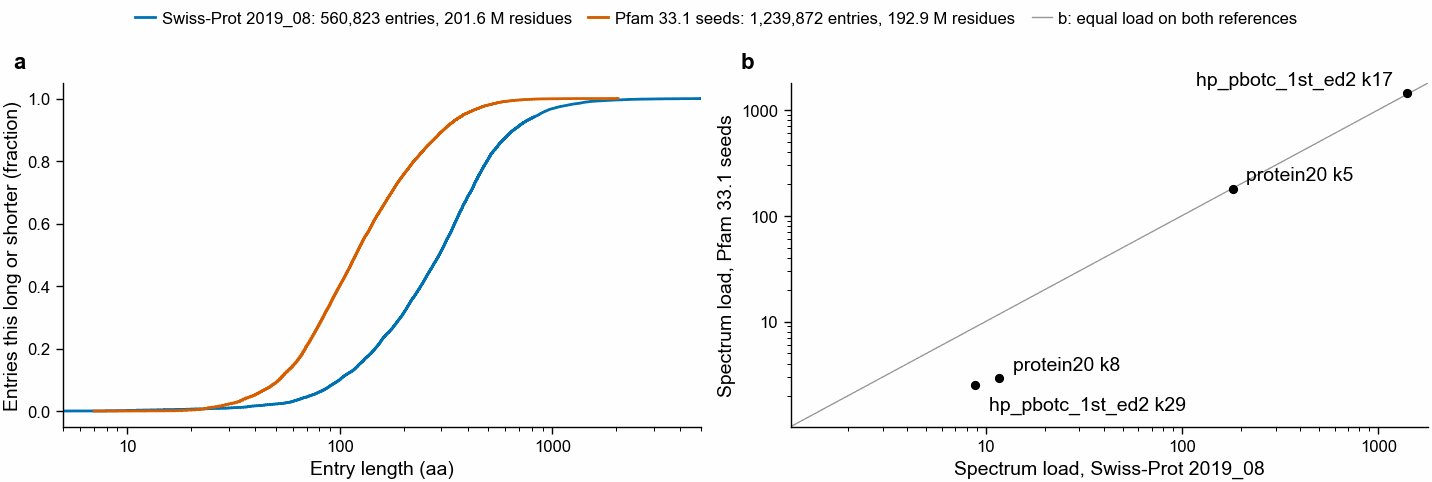

In [5]:
SEED = Path("../nextflow-runs/time-split-pfam/tables/seed_reference")
import json

C = json.loads((SEED / "counts.json").read_text())
rows = [
    ("Pfam 33.1 seed members", C["seed_members"]),
    ("  dropped: accession is a query", C["members_dropped_accession_is_a_query"]),
    (
        "  dropped: residues inside a query",
        C["members_dropped_sequence_inside_a_query"],
    ),
    ("  kept", C["members_kept"]),
    ("entries (distinct sequences)", C["entries"]),
    ("  kept members sharing an entry with another", C["members_sharing_an_entry"]),
    ("  entries in more than one family", C["entries_in_more_than_one_family"]),
    ("families with an entry", C["families_with_an_entry"]),
    ("seed residues", C["residues"]),
    ("Swiss-Prot 2019_08 proteins", C["sprot2019_08_proteins"]),
    ("Swiss-Prot 2019_08 residues", C["sprot2019_08_residues"]),
]
print(pl.DataFrame(rows, schema=["count", "n"], orient="row"))
bits = np.log2(C["sprot2019_08_residues"] / C["residues"])
print(
    f"Arithmetic: log2({C['sprot2019_08_residues']:,} / {C['residues']:,}) = {bits:.3f} bits saved, "
    f"about {bits:.2f} of a letter for a two-letter exact match (1 bit per letter)"
)
print(
    f"median entry length {C['entry_length_median']} aa; letters used: {C['letters']}"
)

LEN = pl.read_csv(SEED / "spectrum_load_lengths.csv")
LOAD = (
    pl.read_csv(SEED / "spectrum_load.csv", infer_schema=False)
    .filter(~pl.col("reference").str.starts_with("check"))
    .with_columns(
        pl.col("ksize").cast(pl.Int64),
        pl.col("load", "predicted_search_gb").cast(pl.Float64),
        pl.col("kmers", "distinct_kmers").cast(pl.Int64),
    )
)
print(LOAD)
print((SEED / "spectrum_load.csv").read_text().splitlines()[-1])
COST = pl.read_csv(SEED / "pilot_trace_cost.csv")
print("Swiss-Prot pilot so far (trace snapshot 2026-10-13 13:22):")
print(COST)

REF_NAME = {
    "reference": "Swiss-Prot 2019_08",
    "reference-pfamseed33_1": "Pfam 33.1 seeds",
}
REF_COLOR = {
    "reference": pf.OKABE_ITO["blue"],
    "reference-pfamseed33_1": pf.OKABE_ITO["vermillion"],
}
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 62, ncols=2)
for ref in REF_NAME:
    t = LEN.filter(pl.col("reference") == ref).sort("length")
    cum = t["entries"].cum_sum() / t["entries"].sum()
    res = (t["length"] * t["entries"]).sum()
    axs[0].step(
        t["length"],
        cum,
        where="post",
        color=REF_COLOR[ref],
        label=f"{REF_NAME[ref]}: {t['entries'].sum():,} entries, {res / 1e6:.1f} M residues",
    )
axs[0].set_xscale("log")
axs[0].set_xlim(5, 5000)
axs[0].xaxis.set_major_formatter(FuncFormatter(lambda v, _p: f"{v:g}"))
axs[0].xaxis.set_minor_formatter(NullFormatter())
axs[0].set_xlabel("Entry length (aa)")
axs[0].set_ylabel("Entries this long or shorter (fraction)")
w = LOAD.pivot(on="reference", index=["alphabet", "ksize"], values="load")
lo, hi = 0.4 * min(w["reference"].min(), w["reference-pfamseed33_1"].min()), 1.25 * max(
    w["reference"].max(), w["reference-pfamseed33_1"].max()
)
axs[1].plot([lo, hi], [lo, hi], color=pf.GREY, lw=0.5)
axs[1].scatter(
    w["reference"], w["reference-pfamseed33_1"], color="black", s=8, zorder=3
)
for a_, k_, x_, y_ in w.select(
    "alphabet", "ksize", "reference", "reference-pfamseed33_1"
).iter_rows():
    # The two low-load points sit close together: one label above, one below.
    dy = -9 if (a_, k_) == ("hp_pbotc_1st_ed2", 29) else 3
    left = x_ > 1000  # the top point's label would leave the panel on the right
    axs[1].annotate(
        f"{a_} k{k_}",
        (x_, y_),
        xytext=(-5 if left else 5, dy),
        textcoords="offset points",
        ha="right" if left else "left",
    )
axs[1].set_xscale("log")
axs[1].set_yscale("log")
axs[1].set_xlim(lo, hi)
axs[1].set_ylim(lo, hi)
for ax_ in (axs[1].xaxis, axs[1].yaxis):
    ax_.set_major_formatter(FuncFormatter(lambda v, _p: f"{v:g}"))
    ax_.set_minor_formatter(NullFormatter())
axs[1].set_xlabel("Spectrum load, Swiss-Prot 2019_08")
axs[1].set_ylabel("Spectrum load, Pfam 33.1 seeds")
handles, labels = axs[0].get_legend_handles_labels()
handles.append(plt.Line2D([], [], color=pf.GREY, lw=0.5))
labels.append("b: equal load on both references")
fig.legend(handles, labels, loc="outside upper center", ncol=3)
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
pf.save(
    fig,
    FIG / "time_split_reference_size_sprot2019_08_vs_pfam33-1_seeds",
    formats=("png", "pdf"),
)

## Stop A. Queries that were already Pfam 33.1 seed members

Expected 0, since every query had no Pfam 33.1 domain. Found: 48 seed members whose
accession is a query and 30 whose residues lie inside a query (some of the 30 are short,
4 aa, and lie inside many unrelated queries and decoys). An instance is *seeded at t0* when
a Pfam 33.1 seed member of the same family is that query's own sequence and overlaps the
instance: Pfam's curators had placed it in the family's seed alignment, but the t0 regions
file, which keeps only hits above the family's gathering threshold on the reference
proteomes, has no row for it. Those instances were known at t0, and hmmscan's t0 model was
built from them. They are dropped from the seed reference; the Swiss-Prot reference cannot
contain them (step 7). Whether to remove them from the scored instances is Olga's call at
Stop A.

How to read the figure (full sample, 9,263 instances): each point is one Pfam type, at the
share of the sample's instances of that type that were seeded at t0; the number beside it is the count. Higher
means more of that type was already known at t0.


pilot: 3 instances seeded at t0 on 1 queries, 1 families
full: 79 instances seeded at t0 on 61 queries, 38 families
shape: (6, 4)
┌─────────────┬─────────────────────┬────────┬──────────┐
│ pfam_type   ┆ instances_in_sample ┆ seeded ┆ pct      │
│ ---         ┆ ---                 ┆ ---    ┆ ---      │
│ enum        ┆ i64                 ┆ u32    ┆ f64      │
╞═════════════╪═════════════════════╪════════╪══════════╡
│ Domain      ┆ 2148                ┆ 9      ┆ 0.418994 │
│ Family      ┆ 2080                ┆ 12     ┆ 0.576923 │
│ Repeat      ┆ 2478                ┆ 16     ┆ 0.645682 │
│ Motif       ┆ 751                 ┆ 20     ┆ 2.663116 │
│ Disordered  ┆ 708                 ┆ 22     ┆ 3.107345 │
│ Coiled-coil ┆ 1098                ┆ 0      ┆ 0.0      │
└─────────────┴─────────────────────┴────────┴──────────┘
P4 instances (Motif, Disordered, Repeat or under 60 aa) among them: 64 of 79
shape: (79, 8)
┌────────────┬──────────┬────────────┬──────────┬────────┬────────────────────────

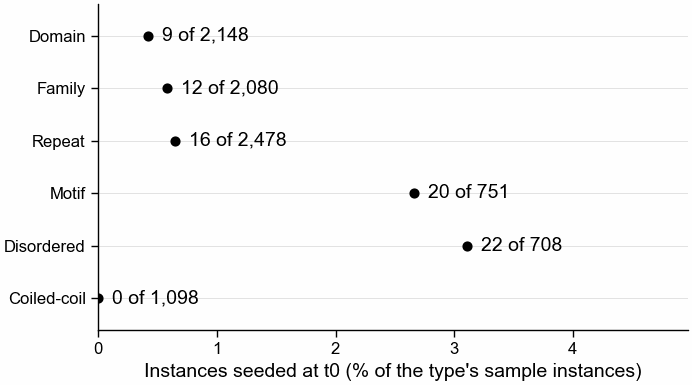

In [6]:
SI = pl.read_csv(SEED / "seeded_instances.csv")
key = ["query", "pfam_acc", "t1_start", "t1_end"]
by = []
for qs in ("pilot", "full"):
    u = SI.filter(pl.col("query_set") == qs).unique(key)
    print(
        f"{qs}: {u.height} instances seeded at t0 on {u['query'].n_unique()} queries, {u['pfam_acc'].n_unique()} families"
    )
u = SI.filter(pl.col("query_set") == "full").unique(key)
t = (
    SAMPLE.select("pfam_type", "instances_in_sample")
    .join(u.group_by("pfam_type").len("seeded"), on="pfam_type", how="left")
    .with_columns(pl.col("seeded").fill_null(0))
    .with_columns(pct=100 * pl.col("seeded") / pl.col("instances_in_sample"))
    .with_columns(pl.col("pfam_type").cast(pl.Enum(TYPES)))
    .sort("pfam_type")
)
print(t)
print(
    f"P4 instances (Motif, Disordered, Repeat or under 60 aa) among them: "
    f"{u.filter(pl.col('pfam_type').is_in(['Motif', 'Disordered', 'Repeat']) | (pl.col('length') < 60)).height} of {u.height}"
)
with pl.Config(tbl_rows=120, tbl_width_chars=200):
    print(
        u.select(
            "query",
            "pfam_acc",
            "pfam_type",
            "t1_start",
            "t1_end",
            "member",
            "on_query_start",
            "on_query_end",
        ).sort("pfam_acc", "query")
    )

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 50)
y = np.arange(t.height)[::-1]
for yy in y:
    ax.axhline(yy, color="#dddddd", lw=0.3, zorder=0)
ax.scatter(t["pct"], y, color="black", s=10, zorder=3)
for yy, p_, n_, d_ in zip(y, t["pct"], t["seeded"], t["instances_in_sample"]):
    ax.annotate(
        f"{n_} of {d_:,}",
        (p_, yy),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
    )
ax.set_yticks(y, t["pfam_type"].cast(pl.String))
ax.set_xlim(0, max(t["pct"]) * 1.6)
ax.set_xlabel("Instances seeded at t0 (% of the type's sample instances)")
ax.set_ylim(-0.6, t.height - 0.4)
pf.save(fig, FIG / "time_split_instances_seeded_at_t0_pfam33-1", formats=("png", "pdf"))

## The pLDDT stratum: AlphaFold confidence of each instance's region

For every instance, the mean pLDDT (AlphaFold's per-residue confidence, 0 to 100; below 50
usually means no fixed structure) of the query's residues inside the t1 domain, read from
the query's AlphaFold model with `read_plddt()` of the QfO benchmark
(`bin/instance_plddt.py`). Models are AlphaFold DB version 4, copied from AlphaFold's Google
Cloud bucket on 2026-10-14 (AlphaFold DB's own file server refused downloads that week).
7,846 of the 8,349 real queries have a model; a sample of 12 of the other 503 have no
AlphaFold DB entry at all. A model counts only when its residues are the query's Pfam 33.1
sequence; otherwise the instance is "no model". The models that the QfO benchmark had
already downloaded covered 64 of these queries.

How to read the figure: each dot is one sample instance, placed at its own mean pLDDT, in the
row of its Pfam type (rows spread a little up and down so dots do not cover each other).
The black tick is the type's median. Instances with no AlphaFold model of the query's
sequence are grey crosses in the "no model" column. The dashed lines at 50 and 70 mark
where the reported strata start: the printed table counts each band, and every recall
number and P4's unique finds are reported in those bands. Results by pLDDT will also be
drawn against pLDDT itself, not only by band. The expectation
written before reading (first cell) is that kmerseek's unique finds, if any, sit mostly in
the below-50 band.


shape: (3, 2)
┌────────────────┬──────┐
│ model          ┆ len  │
│ ---            ┆ ---  │
│ str            ┆ u32  │
╞════════════════╪══════╡
│ none           ┆ 670  │
│ other sequence ┆ 8    │
│ yes            ┆ 8608 │
└────────────────┴──────┘
shape: (6, 6)
┌─────────────┬──────┬───────┬───────┬──────────┬───────┐
│ pfam_type   ┆ < 50 ┆ 50-70 ┆ >= 70 ┆ no model ┆ total │
│ ---         ┆ ---  ┆ ---   ┆ ---   ┆ ---      ┆ ---   │
│ enum        ┆ u32  ┆ u32   ┆ u32   ┆ u32      ┆ u32   │
╞═════════════╪══════╪═══════╪═══════╪══════════╪═══════╡
│ Domain      ┆ 34   ┆ 146   ┆ 1887  ┆ 81       ┆ 2148  │
│ Family      ┆ 56   ┆ 219   ┆ 1689  ┆ 116      ┆ 2080  │
│ Repeat      ┆ 27   ┆ 117   ┆ 2094  ┆ 240      ┆ 2478  │
│ Motif       ┆ 95   ┆ 187   ┆ 430   ┆ 39       ┆ 751   │
│ Disordered  ┆ 213  ┆ 277   ┆ 65    ┆ 153      ┆ 708   │
│ Coiled-coil ┆ 2    ┆ 61    ┆ 986   ┆ 49       ┆ 1098  │
└─────────────┴──────┴───────┴───────┴──────────┴───────┘
lowest mean pLDDT: 26.6
all sample instanc

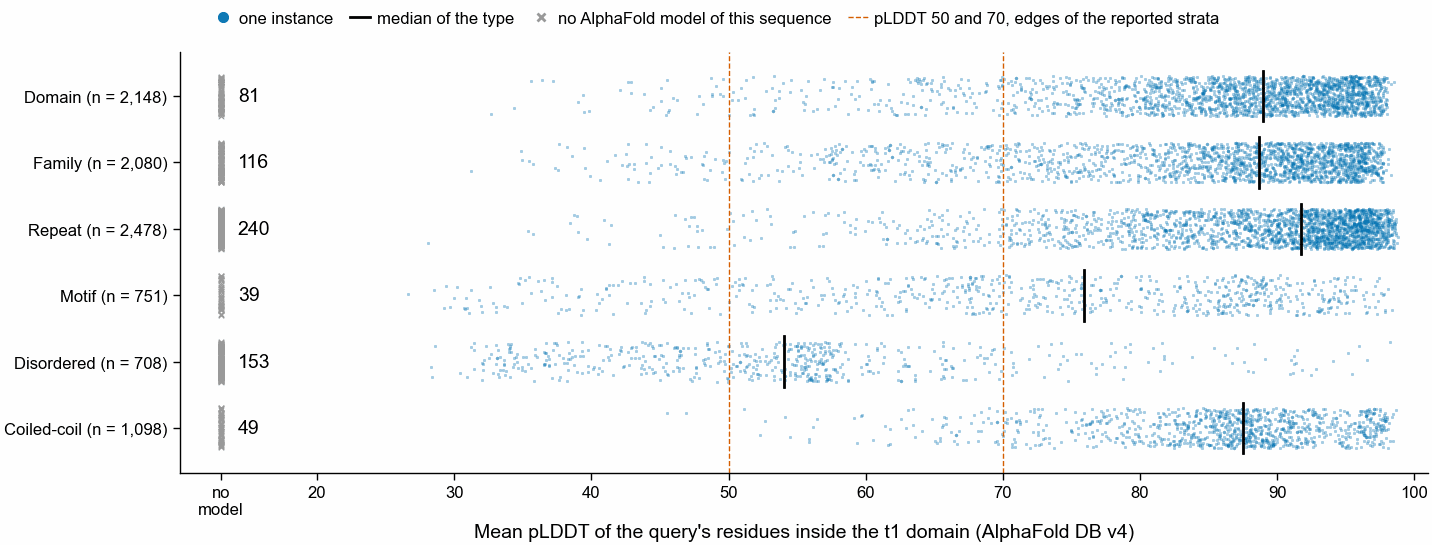

In [7]:
PL = pl.read_csv(
    "../nextflow-runs/time-split-pfam/tables/plddt/instance_plddt.tsv", separator="\t"
)
BANDS = ["< 50", "50-70", ">= 70", "no model"]
BAND_COLOR = {
    "< 50": pf.OKABE_ITO["vermillion"],
    "50-70": pf.OKABE_ITO["orange"],
    ">= 70": pf.OKABE_ITO["blue"],
    "no model": pf.GREY,
}
print(PL.group_by("model").len().sort("model"))
s = PL.filter(pl.col("role") == "sample")
tab = (
    s.group_by("pfam_type", "plddt_band")
    .len()
    .pivot(on="plddt_band", index="pfam_type", values="len")
    .fill_null(0)
    .select("pfam_type", *BANDS)
    .with_columns(pl.col("pfam_type").cast(pl.Enum(TYPES)))
    .sort("pfam_type")
)
tab = tab.with_columns(total=pl.sum_horizontal(*BANDS))
print(tab)
print(f"lowest mean pLDDT: {s['mean_plddt_region'].min():.1f}")
print(
    f"all sample instances: {s.height:,}; "
    + ", ".join(f"{b}: {(s['plddt_band'] == b).sum():,}" for b in BANDS)
)

# Every instance at its own pLDDT, one row per Pfam type; the band edges are drawn only to
# show where the table's strata start. Instances with no model sit in their own column.
rng = np.random.default_rng(280)
fig, ax = pf.figure(pf.TWO_COLUMN_MM, 70)
types = tab["pfam_type"].cast(pl.String).to_list()
ypos = {t: i for i, t in enumerate(types[::-1])}
NO_MODEL_X = 13
for t in types:
    r = s.filter(pl.col("pfam_type") == t)
    have = r.filter(pl.col("mean_plddt_region").is_not_null())
    jit = rng.uniform(-0.3, 0.3, have.height)
    ax.scatter(
        have["mean_plddt_region"],
        ypos[t] + jit,
        s=1.5,
        color=pf.OKABE_ITO["blue"],
        alpha=0.35,
        linewidths=0,
        rasterized=True,
    )
    nm = r.height - have.height
    ax.scatter(
        [NO_MODEL_X] * nm,
        ypos[t] + rng.uniform(-0.3, 0.3, nm),
        s=4,
        marker="x",
        color=pf.GREY,
        linewidths=0.4,
    )
    ax.annotate(
        f"{nm:,}",
        (NO_MODEL_X, ypos[t]),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
    )
    med = have["mean_plddt_region"].median()
    ax.plot([med, med], [ypos[t] - 0.38, ypos[t] + 0.38], color="black", lw=1)
for edge in (50, 70):
    ax.axvline(edge, color=pf.OKABE_ITO["vermillion"], lw=0.5, ls="--")
ax.set_yticks(
    list(ypos.values()),
    [f"{t} (n = {n:,})" for t, n in zip(types[::-1], tab["total"].to_list()[::-1])],
)
ax.set_xticks(
    [NO_MODEL_X, 20, 30, 40, 50, 60, 70, 80, 90, 100],
    ["no\nmodel", "20", "30", "40", "50", "60", "70", "80", "90", "100"],
)
ax.set_xlim(NO_MODEL_X - 3, 101)
ax.set_xlabel(
    "Mean pLDDT of the query's residues inside the t1 domain (AlphaFold DB v4)"
)
from matplotlib.lines import Line2D

fig.legend(
    handles=[
        Line2D(
            [],
            [],
            marker="o",
            ls="",
            color=pf.OKABE_ITO["blue"],
            markersize=3,
            label="one instance",
        ),
        Line2D([], [], color="black", lw=1, label="median of the type"),
        Line2D(
            [],
            [],
            marker="x",
            ls="",
            color=pf.GREY,
            markersize=3,
            label="no AlphaFold model of this sequence",
        ),
        Line2D(
            [],
            [],
            color=pf.OKABE_ITO["vermillion"],
            lw=0.5,
            ls="--",
            label="pLDDT 50 and 70, edges of the reported strata",
        ),
    ],
    loc="outside upper center",
    ncol=4,
)
pf.save(fig, FIG / "time_split_instance_plddt_by_type_afdb_v4", formats=("png", "pdf"))